In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

In [3]:
def mostrar(imagem,titulos,cmap='gray',tamanho=4):
  n = len(imagem)
  plt.figure(figsize=(tamanho*n,tamanho))
  for i in range(n):
    plt.subplot(1,n,i+1)
    plt.imshow(imagem[i],cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()

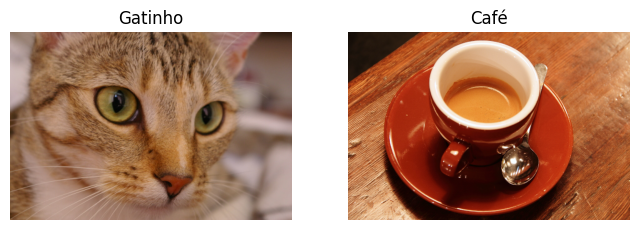

In [4]:
mostrar([data.cat(),data.coffee()],['Gatinho','Café'])

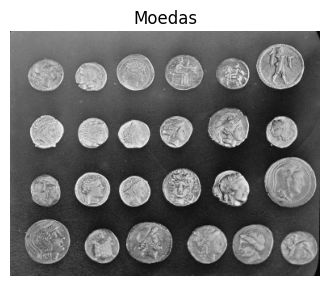

In [5]:
moedas = data.coins()
mostrar([moedas],['Moedas'])

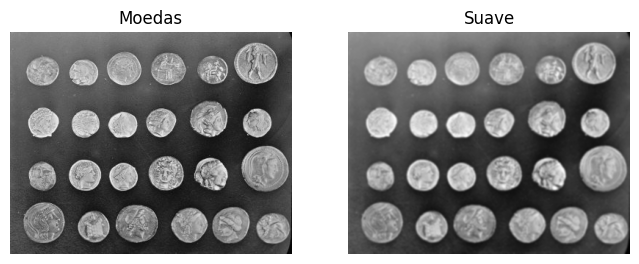

In [6]:
suave = cv2.GaussianBlur(moedas,(5,5),0)
mostrar([moedas,suave],['Moedas','Suave'])

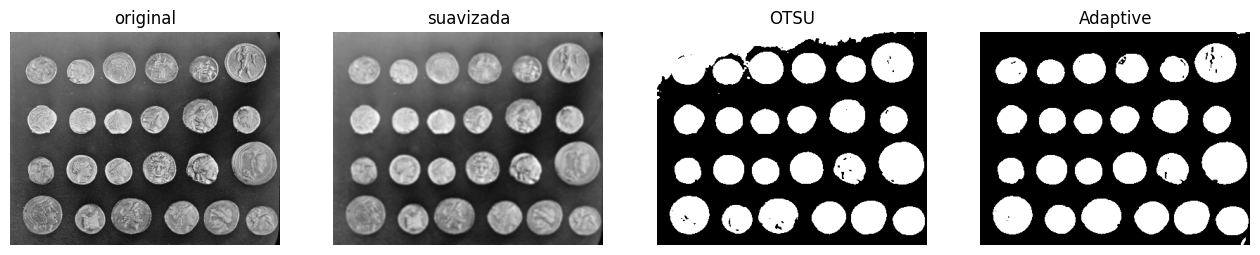

In [7]:
_,mascara_otsu = cv2.threshold(suave,0,255,cv2.THRESH_OTSU + cv2.THRESH_BINARY)
mascara_adapt = cv2.adaptiveThreshold(suave,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,101,-20)

mostrar([moedas, suave, mascara_otsu,mascara_adapt],['original','suavizada','OTSU','Adaptive'])


array([[[ 47,  47,  47],
        [123, 123, 123],
        [133, 133, 133],
        ...,
        [ 14,  14,  14],
        [  3,   3,   3],
        [ 12,  12,  12]],

       [[ 93,  93,  93],
        [144, 144, 144],
        [145, 145, 145],
        ...,
        [ 12,  12,  12],
        [  7,   7,   7],
        [  7,   7,   7]],

       [[126, 126, 126],
        [147, 147, 147],
        [143, 143, 143],
        ...,
        [  2,   2,   2],
        [ 13,  13,  13],
        [  3,   3,   3]],

       ...,

       [[ 81,  81,  81],
        [ 79,  79,  79],
        [ 74,  74,  74],
        ...,
        [  6,   6,   6],
        [  4,   4,   4],
        [  7,   7,   7]],

       [[ 88,  88,  88],
        [ 82,  82,  82],
        [ 74,  74,  74],
        ...,
        [  5,   5,   5],
        [  7,   7,   7],
        [  8,   8,   8]],

       [[ 91,  91,  91],
        [ 79,  79,  79],
        [ 68,  68,  68],
        ...,
        [  4,   4,   4],
        [ 10,  10,  10],
        [  7,   7,   7]]], shape=(303, 384, 3), dtype=uint8)
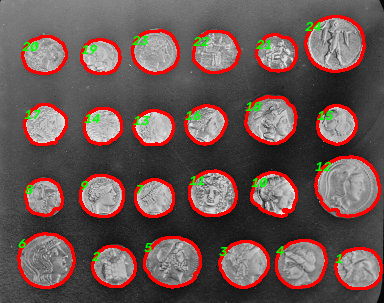

In [8]:
contornos, _ = cv2.findContours(mascara_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Filtro os contornos pequenos
contornos = [c for c in contornos if cv2.contourArea(c) > 500]

# Cria mascara final a partir dos contornos
mascara_final = np.zeros_like(mascara_adapt)

# Desenha os contornos na mascara final
cv2.drawContours(mascara_final, contornos, -1, 255, thickness = -1)

# Converte imagem original cinza em RGB
moedas_rgb = cv2.cvtColor(moedas,cv2.COLOR_GRAY2BGR)

# Sobrepoe os contornos na imagem original
cv2.drawContours(moedas_rgb, contornos, -1, ( 255, 0, 0 ), 2)

for i,c in enumerate(contornos): # Enumerate retorna uma tupla com os indices
  x,y,w,h = cv2.boundingRect(c)
  cv2.putText(moedas_rgb,str(i+1),( x,+ y+15),cv2.FONT_HERSHEY_SCRIPT_SIMPLEX,0.5,(0,255,0),2)
moedas_rgb


